<a href="https://colab.research.google.com/github/laxhidualopez06/Py---1--Laxhidua/blob/main/Pr%C3%A1ctica_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Preparación del entorno y carga de datos**

In [2]:
# Importación de bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Asegúrate de subir el archivo "Mall_Customers.csv" a Colab antes de ejecutar
ruta = "Mall_Customers.csv"
df = pd.read_csv(ruta)

print("Dimensiones:", df.shape)
print("Columnas:", df.columns.tolist())
print("\nValores faltantes:")
print(df.isnull().sum())
display(df.head())

Dimensiones: (200, 5)
Columnas: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Valores faltantes:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# **Exploración 2D y Estandarización**

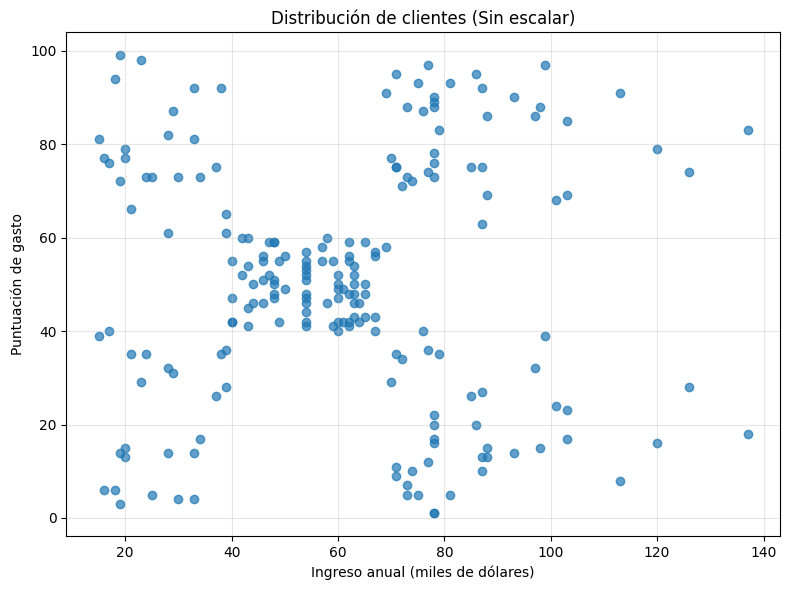

Medias (Estandarizadas):
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Desviaciones estándar:
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


In [3]:
# Seleccionar características 2D
columnas = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[columnas].copy()

# Visualización inicial
plt.figure(figsize=(8, 6))
plt.scatter(X["Annual Income (k$)"], X["Spending Score (1-100)"], alpha=0.7)
plt.title("Distribución de clientes (Sin escalar)")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntuación de gasto")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Estandarización estricta
escalador = StandardScaler()
X_escalado = escalador.fit_transform(X)
df_escalado = pd.DataFrame(X_escalado, columns=columnas)

print("Medias (Estandarizadas):")
print(df_escalado.mean().round(4))
print("\nDesviaciones estándar:")
print(df_escalado.std(ddof=0))

# **Búsqueda del K Óptimo (Codo y Silueta)**

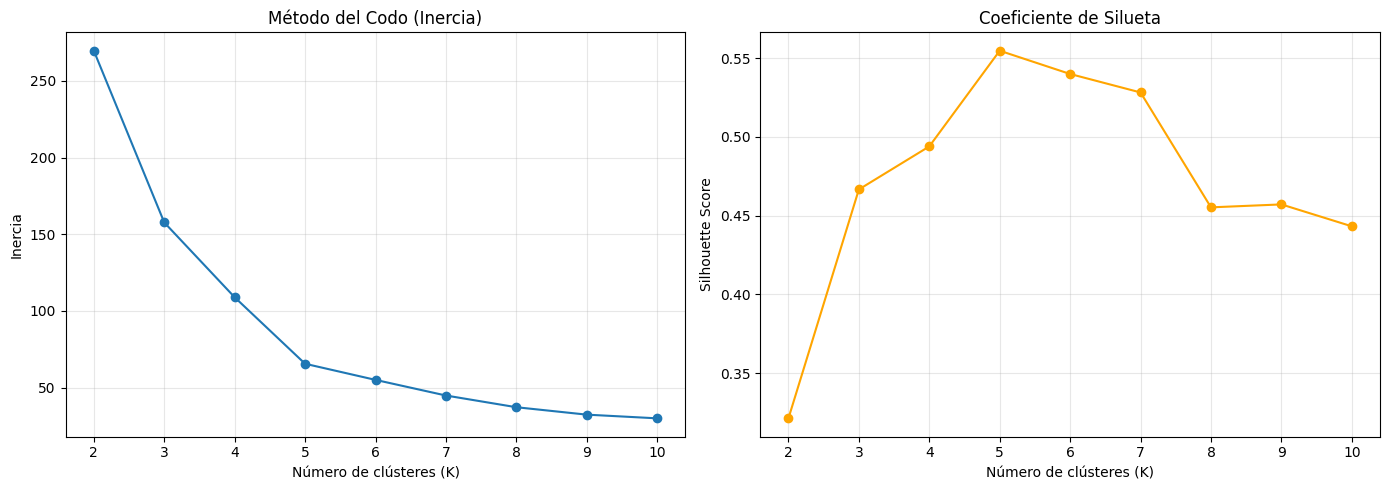

Mejor K según silueta (2D): 5
Coeficiente de silueta máximo: 0.5547


In [4]:
valores_k = range(2, 11)
inercias = []
siluetas = []

for k in valores_k:
    modelo = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = modelo.fit_predict(X_escalado)

    inercias.append(modelo.inertia_)
    siluetas.append(silhouette_score(X_escalado, etiquetas))

# Gráfica del Método del Codo
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(list(valores_k), inercias, marker='o')
plt.title("Método del Codo (Inercia)")
plt.xlabel("Número de clústeres (K)")
plt.ylabel("Inercia")
plt.grid(alpha=0.3)

# Gráfica del Coeficiente de Silueta
plt.subplot(1, 2, 2)
plt.plot(list(valores_k), siluetas, marker='o', color='orange')
plt.title("Coeficiente de Silueta")
plt.xlabel("Número de clústeres (K)")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

indice_mejor = np.argmax(siluetas)
mejor_k = list(valores_k)[indice_mejor]
print(f"Mejor K según silueta (2D): {mejor_k}")
print(f"Coeficiente de silueta máximo: {siluetas[indice_mejor]:.4f}")

# **Entrenamiento Final 2D y Perfilamiento**

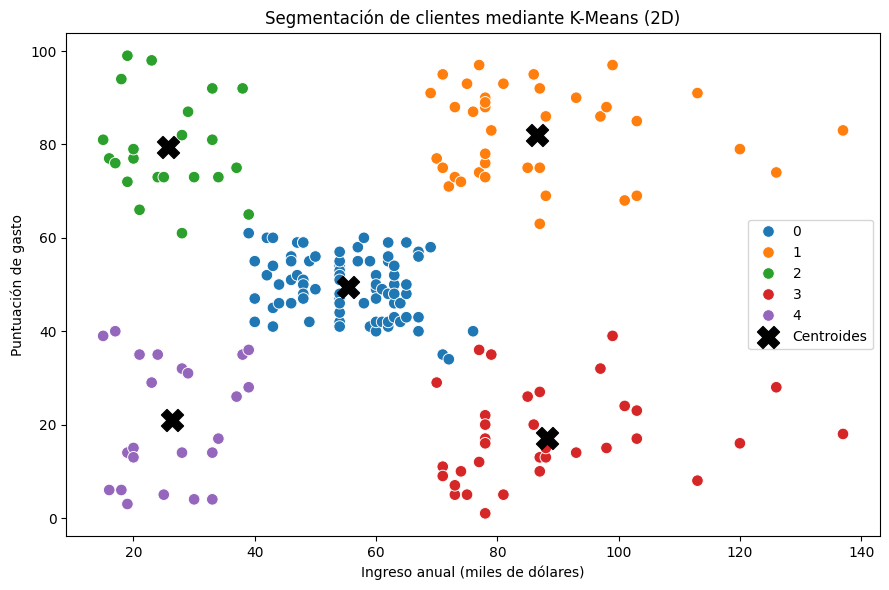

,Annual Income (k$),Spending Score (1-100),Número de clientes
Cluster_2D,,,
0,55.30,49.52,81
1,86.54,82.13,39
2,25.73,79.36,22
3,88.20,17.11,35
4,26.30,20.91,23


In [5]:
# Entrenar modelo con el mejor K (K=5)
modelo_final = KMeans(n_clusters=mejor_k, n_init=10, random_state=42)
etiquetas_finales = modelo_final.fit_predict(X_escalado)

df_final = df.copy()
df_final["Cluster_2D"] = etiquetas_finales

# Visualización de los clústeres
centroides_escalados = modelo_final.cluster_centers_
centroides_originales = escalador.inverse_transform(centroides_escalados)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=df_final, x="Annual Income (k$)", y="Spending Score (1-100)",
                hue="Cluster_2D", palette="tab10", s=70)
plt.scatter(centroides_originales[:, 0], centroides_originales[:, 1],
            marker="X", s=250, c="black", label="Centroides")
plt.title("Segmentación de clientes mediante K-Means (2D)")
plt.xlabel("Ingreso anual (miles de dólares)")
plt.ylabel("Puntuación de gasto")
plt.legend()
plt.tight_layout()
plt.show()

# Profiling del negocio
conteos_finales = df_final.groupby("Cluster_2D").size()
perfil_clusters = df_final.groupby("Cluster_2D")[columnas].mean()
perfil_clusters["Número de clientes"] = conteos_finales
display(perfil_clusters.round(2))

# **Reto (Segmentación Multivariable 3D agregando Edad)**

In [6]:
# Seleccionar variables del reto
variables_reto = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X_reto = df[variables_reto].copy()

# Estandarización 3D
escalador_reto = StandardScaler()
X_reto_escalado = escalador_reto.fit_transform(X_reto)

# Búsqueda de K para 3D
valores_reto = range(2, 11)
resultados_reto = []

for k in valores_reto:
    modelo_reto = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas_reto = modelo_reto.fit_predict(X_reto_escalado)
    resultados_reto.append(silhouette_score(X_reto_escalado, etiquetas_reto))

mejor_k_reto = list(valores_reto)[np.argmax(resultados_reto)]
print(f"Mejor K con tres variables (3D): {mejor_k_reto}")
print(f"Coeficiente de silueta máximo (3D): {max(resultados_reto):.4f}")

# Entrenar modelo 3D final
modelo_3d = KMeans(n_clusters=mejor_k_reto, n_init=10, random_state=42)
df_final["Cluster_3D"] = modelo_3d.fit_predict(X_reto_escalado)

# Profiling del Reto 3D
conteos_3d = df_final.groupby("Cluster_3D").size()
perfil_3d = df_final.groupby("Cluster_3D")[variables_reto].mean()
perfil_3d["Número de clientes"] = conteos_3d
print("\n--- PERFILAMIENTO DEL RETO (EDAD + INGRESO + GASTO) ---")
display(perfil_3d.round(2))

Mejor K con tres variables (3D): 6
Coeficiente de silueta máximo (3D): 0.4284

--- PERFILAMIENTO DEL RETO (EDAD + INGRESO + GASTO) ---


,Age,Annual Income (k$),Spending Score (1-100),Número de clientes
Cluster_3D,,,,
0,56.33,54.27,49.07,45
1,26.79,57.10,48.13,39
2,41.94,88.94,16.97,33
3,32.69,86.54,82.13,39
4,25.00,25.26,77.61,23
5,45.52,26.29,19.38,21
